# Part B — Chart generation

| Section | Charts generated |
| --- | --- |
| [Q2 — Dataset checks](#q2) | Recorded zeros, global-sales concentration, genre counts |
| [Q3 — Sales distributions](#q3) | Boxplots and histograms |
| [Q5 — Regional associations](#q5) | Pairwise scatter plots and regression lines |

**Input:** `data/Video_games_dataset.csv`; one row per title–console record. Sales are in million copies. **Outputs:** CSVs and PNGs under `output/q2/`, `output/q3/` and `output/q5/`.

Run all cells from the project root with the `.venv` kernel:
```sh
.venv/bin/jupyter nbconvert --to notebook --execute --inplace part_b.ipynb
```


## Setup
Run once before the three questions. Quartiles use the medians of the ordered halves (excluding the overall median for odd n); SD uses n − 1. Outliers are strictly outside the 1.5 × IQR cut-offs. These follow the GEA1000 notes.

In [1]:
import logging
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats

%matplotlib inline

DEBUG = False  # True -> show the log.debug lines too

log = logging.getLogger("gea1000")
log.setLevel(logging.DEBUG if DEBUG else logging.INFO)
if not log.handlers:  # dont add a 2nd handler when the cell is rerun
    _handler = logging.StreamHandler(sys.stdout)
    _handler.setFormatter(logging.Formatter("%(message)s"))
    log.addHandler(_handler)
log.propagate = False

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "Video_games_dataset.csv").exists():
    raise FileNotFoundError("Run Part B from the project root.")
DATA_FILE = PROJECT_ROOT / "data" / "Video_games_dataset.csv"

REGIONS = ["NASales", "EUSales", "JapanSales"]
ALL_SALES = ["GlobalSales", "NASales", "EUSales", "JapanSales"]  # no OtherSales

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 50)


def load_data():
    df = pd.read_csv(DATA_FILE)
    log.debug(f"loaded {DATA_FILE.name}: {df.shape[0]} rows, {df.shape[1]} cols")
    return df


OUTPUT_ROOT = PROJECT_ROOT / "output"


def output_folder(question):
    folder = OUTPUT_ROOT / question
    folder.mkdir(parents=True, exist_ok=True)
    return folder


def heading(text):
    line = "=" * 70
    log.info(f"\n{line}\n{text}\n{line}")


def save_table(table, folder, name, index=True):
    table.to_csv(folder / f"{name}.csv", index=index)
    log.info(f"  -> saved {folder.relative_to(PROJECT_ROOT)}/{name}.csv")
    log.debug(f"     ({len(table)} rows)")


def save_figure(fig, folder, name):
    fig.tight_layout()
    fig.savefig(folder / f"{name}.png", dpi=150)
    display(fig)  # show it in the notebook as well
    plt.close(fig)
    log.info(f"  -> saved {folder.relative_to(PROJECT_ROOT)}/{name}.png")

In [2]:



def quartiles(values):
    # notes method (eg 3.1.20): Q1/Q3 = median of lower/upper half,
    # leave out the middle value if n is odd. pandas quantile() interpolates so dont use that
    s = np.sort(np.asarray(values, dtype=float))
    n = len(s)
    half = n // 2

    lower = s[:half]
    upper = s[half + n % 2:]
    # log.debug(f"halves: {len(lower)} / {len(upper)}")

    return float(np.median(lower)), float(np.median(s)), float(np.median(upper))


def five_number_summary(values):
    # + IQR and outlier cut-offs (def 3.1.44)
    values = pd.Series(values, dtype=float)
    q1, med, q3 = quartiles(values)

    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    n_out = ((values < lower_fence) | (values > upper_fence)).sum()
    log.debug(f"five num summary: q1={q1} med={med} q3={q3} iqr={iqr:.3f} outliers={n_out}")

    return {
        "Min": values.min(),
        "Q1": q1,
        "Median": med,
        "Q3": q3,
        "Max": values.max(),
        "IQR": iqr,
        "Lower cut-off (Q1-1.5IQR)": lower_fence,
        "Upper cut-off (Q3+1.5IQR)": upper_fence,
        "Outliers": int(n_out),
    }


def describe_r(r):
    # rule of thumb from notes: 0.7+ strong, 0.3-0.7 moderate, under 0.3 weak
    if abs(r) >= 0.7:
        strength = "strong"
    elif abs(r) >= 0.3:
        strength = "moderate"
    else:
        strength = "weak"

    if r > 0:
        direction = "positive"
    elif r < 0:
        direction = "negative"
    else:
        direction = "no"

    return f"{strength} {direction} linear association"

In [3]:

# colourblind safe-ish. blue = main, orange = stuff we're pointing out, grey = background
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#b5b3ad"

INK = "#0b0b0b"
MUTED = "#52514e"  # for labels/annotations

BACKGROUND = "#fcfcfb"


def use_house_style() -> None:
    plt.rcParams.update({
        "figure.facecolor": BACKGROUND,
        "axes.facecolor": BACKGROUND,
        "axes.edgecolor": "#898781",
        "axes.labelcolor": MUTED,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "font.size": 10,
    })

use_house_style()

<a id="q2"></a>
# Q2 — Dataset checks
Generate the three dataset-check charts below.

In [4]:
# shared bits for the q2 charts

games = load_data()
out = output_folder("q2")

FIG_SIZE = (8, 4.5)  # (9, 5) was too big in the doc

def label_bars(ax, bars, fmt="{:,.0f}"):
    # puts the value on top of each bar
    for bar in bars:
        height = bar.get_height()
        x_middle = bar.get_x() + bar.get_width() / 2
        ax.text(x_middle, height, fmt.format(height), ha="center", va="bottom", color=MUTED)

def legend_from_colours(ax, items):
    # items = [(colour, label), ...]
    handles = [plt.Rectangle((0, 0), 1, 1, color=colour) for colour, _ in items]
    labels = [label for _, label in items]
    ax.legend(handles=handles, labels=labels, frameon=False)

### 1. Recorded zeros
Count entries equal to zero in each regional sales column and divide by the total record count.

In [5]:
heading("Q2 point 1: zero sales (possible missing data recorded as 0)")

zeros = (games[ALL_SALES] == 0).sum().rename("Rows with 0")
log.info(zeros.to_string())
save_table(zeros.to_frame(), out, "zero_sales_counts")


Q2 point 1: zero sales (possible missing data recorded as 0)


GlobalSales       0
NASales           0
EUSales         482
JapanSales     1150


  -> saved output/q2/zero_sales_counts.csv


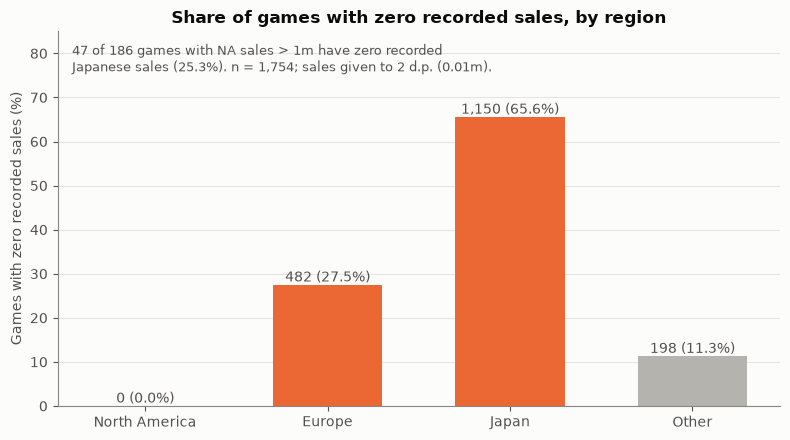

  -> saved output/q2/p1_zero_sales_by_region.png


In [6]:
# ---- point 1: zero sales by region ----

region_names = {
    "NASales": "North America",
    "EUSales": "Europe",
    "JapanSales": "Japan",
    "OtherSales": "Other",
}
is_zero = games[list(region_names)] == 0
zero_count = is_zero.sum()
zero_percent = is_zero.mean() * 100
log.debug(f"zero %:\n{zero_percent.round(1)}")

fig, ax = plt.subplots(figsize=FIG_SIZE)
bar_colours = [GREY, ORANGE, ORANGE, GREY]  # EU + Japan highlighted
bars = ax.bar(list(region_names.values()), zero_percent.to_numpy(), color=bar_colours, width=0.6)

for bar, count, pct in zip(bars, zero_count, zero_percent):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{count:,} ({pct:.1f}%)",
            ha="center", va="bottom", color=MUTED)

# Compare recorded zeros among high-selling NA records.
na_hits = games["NASales"] > 1
na_hits_zero_japan = (na_hits & (games["JapanSales"] == 0)).sum()
log.debug(f"na hits = {na_hits.sum()}, of which jp=0: {na_hits_zero_japan}")
note = (f"{na_hits_zero_japan} of {na_hits.sum()} games with NA sales > 1m have zero recorded\n"
        f"Japanese sales ({na_hits_zero_japan / na_hits.sum():.1%}). "
        f"n = {len(games):,}; sales given to 2 d.p. (0.01m).")
ax.text(0.02, 0.97, note, transform=ax.transAxes, va="top", color=MUTED, fontsize=9)

ax.set_ylabel("Games with zero recorded sales (%)")
ax.set_ylim(0, 85)
ax.set_title("Share of games with zero recorded sales, by region")
ax.grid(axis="x", visible=False)
save_figure(fig, out, "p1_zero_sales_by_region")

### 2. Global-sales concentration
Sort records by global sales. Plot the boxplot alongside the shares of records and sales in the top 10%, next 40% and bottom 50%.

In [7]:
heading("Q2 point 2: skew + concentration of GlobalSales")

g = games["GlobalSales"]
s = five_number_summary(g)
log.info(f"mean {g.mean():.2f}, median {s['Median']:.2f}, SD {g.std():.2f}")
log.info(f"Q1 {s['Q1']:.2f}, Q3 {s['Q3']:.2f}, IQR {s['Q3'] - s['Q1']:.2f}")
log.info(f"upper cut-off {s['Upper cut-off (Q3+1.5IQR)']:.2f}, outliers above it: {s['Outliers']}")

ranked = g.sort_values(ascending=False).to_numpy()
top10pct = round(len(ranked) * 0.10)
log.info(f"top 10% ({top10pct} games) = {ranked[:top10pct].sum() / ranked.sum():.1%} of global sales")
log.info(f"bottom 50% = {ranked[round(len(ranked) * 0.50):].sum() / ranked.sum():.1%}")

cols = ["Title", "Console", "YearReleased", "GlobalSales", "NASales", "EUSales", "JapanSales"]
top10 = games.nlargest(10, "GlobalSales")
log.info(top10[cols].to_string(index=False))
save_table(top10[cols], out, "top10_global_sales", index=False)


Q2 point 2: skew + concentration of GlobalSales


mean 1.00, median 0.34, SD 2.51


Q1 0.14, Q3 0.90, IQR 0.76


upper cut-off 2.04, outliers above it: 186


top 10% (175 games) = 57.8% of global sales


bottom 50% = 7.7%


                                       Title      Console  YearReleased  GlobalSales  NASales  EUSales  JapanSales
                              Mario Kart Wii Nintendo Wii          2008        35.83    15.85    12.88        3.79
                           Wii Sports Resort Nintendo Wii          2009        33.00    15.75    11.01        3.28
                       New Super Mario Bros.  Nintendo DS          2006        30.01    11.38     9.23        6.50
                                    Wii Play Nintendo Wii          2006        29.01    14.03     9.20        2.93
                   New Super Mario Bros. Wii Nintendo Wii          2009        28.61    14.59     7.06        4.70
                                  Nintendogs  Nintendo DS          2005        24.75     9.07    11.00        1.93
                               Mario Kart DS  Nintendo DS          2005        23.43     9.81     7.57        4.13
                                     Wii Fit Nintendo Wii          2007        2

  -> saved output/q2/top10_global_sales.csv


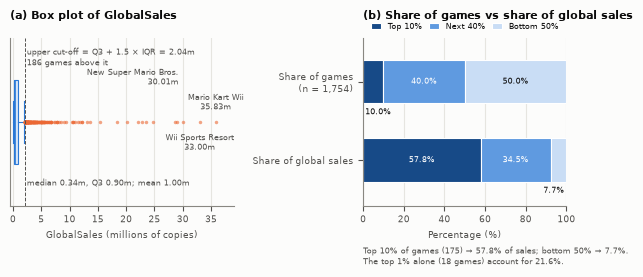

In [8]:
# ---- point 2: sales concentrated in a few best sellers ----
# this one goes in the report at actual size -> smaller fonts, higher dpi

sales_high_to_low = games["GlobalSales"].sort_values(ascending=False).to_numpy()
n_games = len(sales_high_to_low)
total_sales = sales_high_to_low.sum()

# top 10% / next 40% / bottom 50%
cut_points = [0, round(n_games * 0.10), round(n_games * 0.50), n_games]
tier_names = ["Top 10%", "Next 40%", "Bottom 50%"]
tier_colours = ["#174a87", "#5f9ae0", "#c9ddf5"]  # darkest = best sellers

games_percent = np.diff(cut_points) / n_games * 100
sales_percent = np.array([
    sales_high_to_low[start:end].sum() for start, end in zip(cut_points, cut_points[1:])
]) / total_sales * 100

top1_count = round(n_games * 0.01)
top1_percent = sales_high_to_low[:top1_count].sum() / total_sales * 100
log.debug(f"cuts={cut_points} sales%={sales_percent.round(2)} top1%={top1_percent:.2f}")

summary = five_number_summary(games["GlobalSales"])
upper_fence = summary["Upper cut-off (Q3+1.5IQR)"]

plt.rcParams.update({"font.size": 6.5})
fig, (ax_box, ax_bars) = plt.subplots(1, 2, figsize=(6.3, 2.9), width_ratios=[1.1, 1])  # A4 text width

# (a) boxplot - best sellers way past the cut-off
ax_box.boxplot(
    games["GlobalSales"],
    orientation="horizontal",
    widths=0.5,
    patch_artist=True,
    boxprops=dict(facecolor="#d6e6f8", edgecolor=BLUE, linewidth=0.8),
    medianprops=dict(color=BLUE, linewidth=1.2),
    whiskerprops=dict(color=BLUE, linewidth=0.8),
    capprops=dict(color=BLUE, linewidth=0.8),
    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.6),
)
ax_box.axvline(upper_fence, color=MUTED, linestyle="--", linewidth=0.7)
ax_box.text(upper_fence + 0.4, 1.45,
            f"upper cut-off = Q3 + 1.5 × IQR = {upper_fence:.2f}m\n{summary['Outliers']} games above it",
            color=MUTED, fontsize=6, va="top")
ax_box.text(upper_fence + 0.4, 0.62,
            f"median {summary['Median']:.2f}m, Q3 {summary['Q3']:.2f}m; "
            f"mean {games['GlobalSales'].mean():.2f}m",
            color=MUTED, fontsize=6)

# Stagger top-title labels at three heights to avoid collisions.
top3 = games.nlargest(3, "GlobalSales")[["Title", "GlobalSales"]]
label_positions = [(0, 14, "center"), (0, -15, "center"), (-3, 32, "right")]
for (title, sales), (dx, dy, align) in zip(top3.itertuples(index=False), label_positions):
    ax_box.annotate(f"{title}\n{sales:.2f}m", (sales, 1), xytext=(dx, dy), textcoords="offset points",
                    ha=align, va="center", color=MUTED, fontsize=5.5)

ax_box.set_yticks([])
ax_box.set_ylim(0.5, 1.5)
ax_box.set_xlim(-0.5, 39)  # wii sports is ~35, leave room for label
ax_box.set_xlabel("GlobalSales (millions of copies)")
ax_box.set_title("(a) Box plot of GlobalSales", loc="left", fontsize=8, pad=14)
ax_box.grid(axis="y", visible=False)

# (b) share of games vs share of sales
for row, percentages in enumerate([games_percent, sales_percent]):
    left = 0
    for pct, colour, tier in zip(percentages, tier_colours, tier_names):
        ax_bars.barh(row, pct, left=left, color=colour, height=0.55, edgecolor="white", linewidth=0.8,
                     label=tier if row == 0 else None)
        text_colour = "#0b0b0b" if colour == tier_colours[-1] else "white"  # dark text on the light bit
        if pct < 15:
            # Put narrow-segment labels below the bar, inside the plot's x extent.
            x_label = left + 1 if left == 0 else left + pct - 1
            align = "left" if left == 0 else "right"
            ax_bars.text(x_label, row + 0.39, f"{pct:.1f}%", ha=align,
                         va="center", fontsize=5.5, color=INK)
        else:
            ax_bars.text(left + pct / 2, row, f"{pct:.1f}%", ha="center", va="center",
                         fontsize=5.5, color=text_colour)
        left += pct

ax_bars.set_yticks([0, 1], [f"Share of games\n(n = {n_games:,})", "Share of global sales"])
ax_bars.set_ylim(1.58, -0.55)
ax_bars.set_xlim(0, 100)
ax_bars.set_xlabel("Percentage (%)")
ax_bars.text(0, -0.24,
             f"Top 10% of games ({cut_points[1]}) → {sales_percent[0]:.1f}% of sales; "
             f"bottom 50% → {sales_percent[2]:.1f}%.\n"
             f"The top 1% alone ({top1_count} games) account for {top1_percent:.1f}%.",
             transform=ax_bars.transAxes, va="top", color=MUTED, fontsize=6)
ax_bars.legend(frameon=False, ncol=3, fontsize=6, handlelength=1.2, columnspacing=0.8,
               loc="lower right", bbox_to_anchor=(1.0, 1.0))
ax_bars.set_title("(b) Share of games vs share of global sales", loc="left", fontsize=8, pad=14)
ax_bars.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(out / "p2_sales_concentration.png", dpi=300, bbox_inches="tight")
display(fig)
plt.close(fig)
plt.rcParams.update({"font.size": 10})  # reset

### 3. Genre counts
Count comma-separated genre labels per record, then plot the frequency of each count.

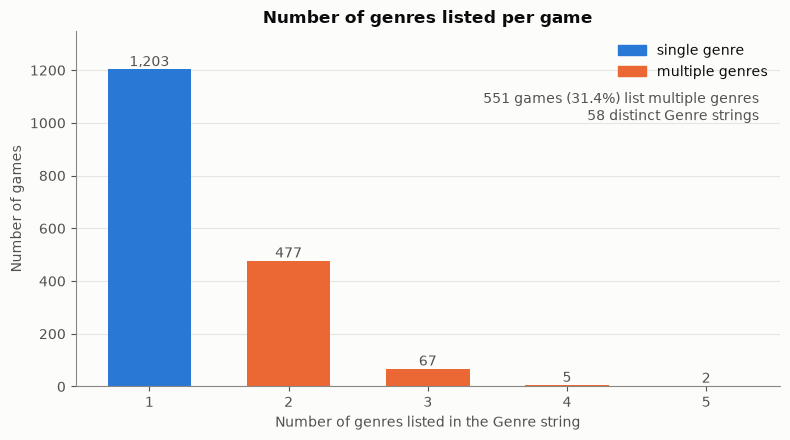

  -> saved output/q2/p8_genres_per_game.png


In [9]:
# Count genre labels per title–console record.

genres_per_game = (games["Genre"].str.count(",") + 1).value_counts().sort_index()  # commas + 1
is_multi = genres_per_game.index > 1
log.debug(f"genres per game:\n{genres_per_game}")

fig, ax = plt.subplots(figsize=FIG_SIZE)
bars = ax.bar(genres_per_game.index.astype(str), genres_per_game.to_numpy(),
              color=np.where(is_multi, ORANGE, BLUE), width=0.6)
label_bars(ax, bars)
ax.set_xlabel("Number of genres listed in the Genre string")
ax.set_ylabel("Number of games")
ax.set_ylim(0, genres_per_game.max() * 1.12)

n_multi = genres_per_game[is_multi].sum()
ax.text(0.97, 0.75,
        f"{n_multi} games ({n_multi / len(games):.1%}) list multiple genres\n"
        f"{games['Genre'].nunique()} distinct Genre strings",
        transform=ax.transAxes, ha="right", color=MUTED)
ax.set_title("Number of genres listed per game")
legend_from_colours(ax, [(BLUE, "single genre"), (ORANGE, "multiple genres")])
ax.grid(axis="x", visible=False)
save_figure(fig, out, "p8_genres_per_game")

<a id="q3"></a>
# Q3 — Sales distributions
Calculate summary statistics and generate boxplots and histograms for Global, NA, EU and Japan sales.

In [10]:
# Q3 - sales distributions: summary stats, boxplots, histograms
# following section 3.1 of the notes (outliers = beyond Q3 + 1.5 IQR / below Q1 - 1.5 IQR)

df = load_data()
out = output_folder("q3")

In [11]:
heading("Q3. Summary statistics (millions of copies)")

rows = {}
for column in ALL_SALES:
    sales = df[column]
    log.debug(f"{column}: n={len(sales)} mean={sales.mean():.4f}")
    rows[column] = {
        "n": len(sales),
        "Mean": sales.mean(),
        "SD": sales.std(),  # sample sd, n-1 (def 3.1.13)
        **five_number_summary(sales),
        "Range": sales.max() - sales.min(),
        "Mode": ", ".join(map(str, sales.mode())),
        "Coefficient of variation (SD/mean)": sales.std() / sales.mean(),  # def 3.1.22
        "% of games with 0 sales": (sales == 0).mean() * 100,
    }

summary_table = pd.DataFrame(rows).T
display(summary_table[["Mean", "SD", "Min", "Q1", "Median", "Q3", "Max"]].astype(float).round(3))
save_table(summary_table, out, "summary_statistics")


Q3. Summary statistics (millions of copies)


,Mean,SD,Min,Q1,Median,Q3,Max
GlobalSales,0.996,2.513,0.01,0.14,0.34,0.90,35.83
NASales,0.506,1.138,0.01,0.10,0.20,0.46,15.85
EUSales,0.289,0.854,0.00,0.00,0.03,0.27,12.88
JapanSales,0.094,0.448,0.00,0.00,0.00,0.02,6.50


  -> saved output/q3/summary_statistics.csv


In [12]:
# boxplots - pass our own quartiles in, otherwise matplotlib uses its own method
def box_from_notes(column: str) -> dict:
    sales = df[column]
    summary = five_number_summary(sales)

    # whiskers go to the furthest points still inside the cut-offs
    inside = sales[(sales >= summary["Lower cut-off (Q1-1.5IQR)"]) & (sales <= summary["Upper cut-off (Q3+1.5IQR)"])]
    outliers = sales[(sales < inside.min()) | (sales > inside.max())]

    return {
        "label": column,
        "q1": summary["Q1"],
        "med": summary["Median"],
        "q3": summary["Q3"],
        "whislo": inside.min(),
        "whishi": inside.max(),
        "fliers": outliers.to_numpy(),
    }


zoom_settings = {"GlobalSales": (2.0, 0.05), "NASales": (1.0, 0.025),
                 "EUSales": (0.7, 0.02), "JapanSales": (0.1, 0.01)}

### Paired boxplots and histograms
Boxes and whiskers use all records; outlier markers are hidden. Histograms use the labelled cut-offs and bin widths. Scales differ across panels.

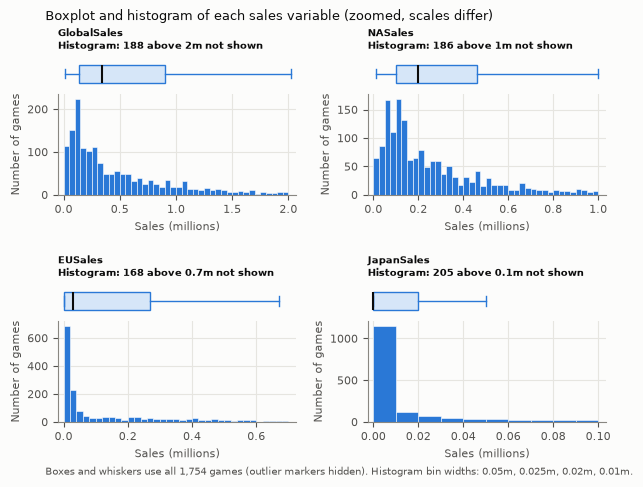

  -> saved output/q3/optB_paired_distributions.png


In [13]:
plt.rcParams.update({"font.size": 8})
fig = plt.figure(figsize=(6.3, 4.8))  # A4 text width
grid = fig.add_gridspec(2, 2, hspace=0.65, wspace=0.3)

for i, column in enumerate(ALL_SALES):
    upper, width = zoom_settings[column]
    sales = df[column]
    inner = grid[i // 2, i % 2].subgridspec(2, 1, height_ratios=[1, 3], hspace=0.05)
    ax_box = fig.add_subplot(inner[0])
    ax_hist = fig.add_subplot(inner[1], sharex=ax_box)

    # same quartiles/whiskers as the notes (box_from_notes from the boxplot cell)
    ax_box.bxp([box_from_notes(column)], orientation="horizontal", showfliers=False, widths=0.55,
               patch_artist=True, boxprops={"facecolor": "#d6e6f8", "edgecolor": BLUE},
               medianprops={"color": INK, "linewidth": 1.5},
               whiskerprops={"color": BLUE}, capprops={"color": BLUE})
    ax_box.set_yticks([])
    ax_box.tick_params(axis="x", bottom=False, labelbottom=False)
    ax_box.spines[["left", "bottom"]].set_visible(False)
    ax_box.grid(False)
    n_hidden = (sales > upper).sum()
    ax_box.set_title(f"{column}\nHistogram: {n_hidden} above {upper:g}m not shown", loc="left", fontsize=7.5)

    bin_edges = [k * width for k in range(round(upper / width) + 1)]
    ax_hist.hist(sales[sales <= upper], bins=bin_edges, color=BLUE, edgecolor="white", linewidth=0.4)
    ax_hist.set_xlim(-upper * 0.025, upper * 1.035)
    ax_hist.set_xlabel("Sales (millions)")
    ax_hist.set_ylabel("Number of games")
    log.debug(f"{column} optB: whiskers {box_from_notes(column)['whislo']}-{box_from_notes(column)['whishi']}")

fig.suptitle("Boxplot and histogram of each sales variable (zoomed, scales differ)", fontsize=9, x=0.08, ha="left")
fig.text(0.08, 0.01, "Boxes and whiskers use all 1,754 games (outlier markers hidden). Histogram bin widths: "
         "0.05m, 0.025m, 0.02m, 0.01m.", fontsize=7, color=MUTED)
fig.subplots_adjust(left=0.1, right=0.97, top=0.88, bottom=0.12)
fig.savefig(out / "optB_paired_distributions.png", dpi=300)
display(fig)
plt.close(fig)
plt.rcParams.update({"font.size": 10})  # reset
log.info(f"  -> saved output/q3/optB_paired_distributions.png")

<a id="q5"></a>
# Q5 — Regional associations
Fit least-squares lines for each pair of regions. Each point represents one title–console record. Plot NA → EU, NA → Japan and EU → Japan.

In [14]:
# Q5 - association between regional sales, for each pair of regions
# notes sections 3.2-3.5: scatter plots, r, linear regression Y = mX + b
# exponential model (discussion 3.5.5): ln(Y) on X  ->  Y = c * b^X, needs Y > 0
# also tried ln-ln (power) model - NOT in the notes, labelled "beyond notes"

games = load_data()
out = output_folder("q5")

REGION_PAIRS = list(combinations(REGIONS, 2))  # NA-EU, NA-JP, EU-JP

In [15]:
heading("Q5. Correlation coefficient r for each pair of regions")

correlations = games[REGIONS].corr()
log.info(correlations.round(3).to_string())
for x_col, y_col in REGION_PAIRS:
    r = correlations.loc[x_col, y_col]
    log.info(f"  {x_col} & {y_col}: r = {r:.3f} -> {describe_r(r)}")
save_table(correlations.round(4), out, "correlation_matrix")


Q5. Correlation coefficient r for each pair of regions


            NASales  EUSales  JapanSales
NASales       1.000    0.894       0.646
EUSales       0.894    1.000       0.709
JapanSales    0.646    0.709       1.000


  NASales & EUSales: r = 0.894 -> strong positive linear association


  NASales & JapanSales: r = 0.646 -> moderate positive linear association


  EUSales & JapanSales: r = 0.709 -> strong positive linear association


  -> saved output/q5/correlation_matrix.csv


In [16]:
def equation(y: str, m: float, x: str, b: float) -> str:
    sign = "-" if b < 0 else "+"
    return f"{y} = {m:.4f} * {x} {sign} {abs(b):.4f}"

def fit_line(x: pd.Series, y: pd.Series, x_label: str, y_label: str, model: str) -> dict:
    # least squares, returns one row for the results table
    result = stats.linregress(x, y)
    log.debug(f"fit {y_label} ~ {x_label} ({model}): n={len(x)} m={result.slope:.4f} r={result.rvalue:.4f}")
    return {
        "X": x_label,
        "Y": y_label,
        "Model": model,
        "n": len(x),
        "m (gradient)": result.slope,
        "b (y-intercept)": result.intercept,
        "r": result.rvalue,
        "Strength": describe_r(result.rvalue),
        "X range in data": f"{x.min():g} to {x.max():g}",
    }

In [17]:
rows = []
for x_col, y_col in REGION_PAIRS:
    # both directions since Y on X != X on Y (remark 3.5.4)
    for x_name, y_name in [(x_col, y_col), (y_col, x_col)]:
        x = games[x_name]
        y = games[y_name]

        # linear
        linear = fit_line(x, y, x_name, y_name, "Linear")
        linear["Equation"] = equation(y_name, linear["m (gradient)"], x_name, linear["b (y-intercept)"])
        linear["Check m = r * sY/sX"] = linear["r"] * y.std() / x.std()  # should match m
        rows.append(linear)

        # exponential - drop Y = 0, cant ln 0
        y_positive = y > 0
        log.debug(f"{y_name}: dropping {(~y_positive).sum()} zero rows for ln")
        exponential = fit_line(x[y_positive], np.log(y[y_positive]), x_name, f"ln({y_name})",
                               "Exponential (ln Y vs X, Y > 0)")
        c = np.exp(exponential["b (y-intercept)"])
        b = np.exp(exponential["m (gradient)"])
        exponential["Equation"] = (
            equation(f"ln({y_name})", exponential["m (gradient)"], x_name, exponential["b (y-intercept)"])
            + f"  =>  {y_name} = {c:.4f} * {b:.4f}^{x_name}"
        )
        rows.append(exponential)

        # power (beyond notes) - need both X and Y > 0
        both_positive = (x > 0) & (y > 0)
        power = fit_line(np.log(x[both_positive]), np.log(y[both_positive]),
                         f"ln({x_name})", f"ln({y_name})", "Power (ln Y vs ln X, beyond notes)")
        k = np.exp(power["b (y-intercept)"])
        power["Equation"] = (
            equation(f"ln({y_name})", power["m (gradient)"], f"ln({x_name})", power["b (y-intercept)"])
            + f"  =>  {y_name} = {k:.4f} * {x_name}^{power['m (gradient)']:.4f}"
        )
        rows.append(power)

models = pd.DataFrame(rows)
log.debug(f"{len(models)} models fitted")  # should be 18

In [18]:
save_table(models.round(4), out, "regression_models", index=False)
top10_index = games["GlobalSales"].nlargest(10).index
without_top10 = games.drop(index=top10_index)
prediction_rows = []
for x_col, y_col in REGION_PAIRS:
    fit = stats.linregress(games[x_col], games[y_col])
    predicted = fit.slope * games[x_col] + fit.intercept
    prediction_rows.append({
        "Predict Y from X": f"{y_col} from {x_col}",
        "Equation": equation(y_col, fit.slope, x_col, fit.intercept),
        "r": fit.rvalue,
        "r without top 10": without_top10[x_col].corr(without_top10[y_col]),
        "Negative predictions (%)": 100 * (predicted < 0).mean(),
        "Observed X range (m)": f"{games[x_col].min():g}–{games[x_col].max():g}",
    })
prediction_summary = pd.DataFrame(prediction_rows)
display(prediction_summary.round(4))
save_table(prediction_summary, out, "prediction_summary", index=False)

  -> saved output/q5/regression_models.csv


,Predict Y from X,Equation,r,r without top 10,Negative predictions (%),Observed X range (m)
0,EUSales from NASales,EUSales = 0.6711 * NASales - 0.0502,0.8944,0.8065,18.0730,0.01–15.85
1,JapanSales from NASales,JapanSales = 0.2540 * NASales - 0.0344,0.6459,0.3958,36.6591,0.01–15.85
2,JapanSales from EUSales,JapanSales = 0.3715 * EUSales - 0.0134,0.7087,0.5017,51.9384,0–12.88


  -> saved output/q5/prediction_summary.csv


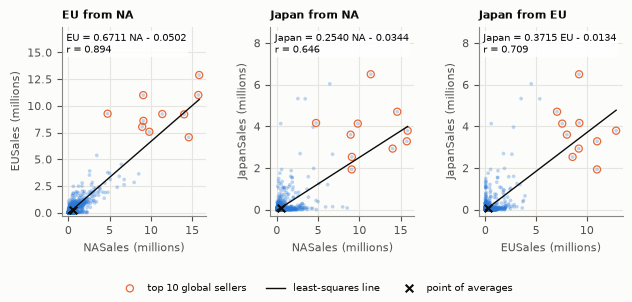

  -> saved output/q5/optB_linear_pairs.png


In [19]:
plt.rcParams.update({"font.size": 8})
top10_index = games["GlobalSales"].nlargest(10).index
short = {"NASales": "NA", "EUSales": "EU", "JapanSales": "Japan"}

fig, axes = plt.subplots(1, 3, figsize=(6.3, 3.0))
for ax, (x_col, y_col) in zip(axes, REGION_PAIRS):
    x = games[x_col]
    y = games[y_col]
    result = stats.linregress(x, y)

    ax.scatter(x, y, s=7, alpha=0.3, color=BLUE, edgecolors="none")
    ax.scatter(x[top10_index], y[top10_index], s=26, facecolors="none", edgecolors=ORANGE, linewidths=0.9,
               label="top 10 global sellers")
    xs = np.array([x.min(), x.max()])  # only draw the line over the X range we have
    ax.plot(xs, result.slope * xs + result.intercept, color=INK, linewidth=1, label="least-squares line")
    ax.scatter([x.mean()], [y.mean()], marker="x", color=INK, s=30, zorder=5, label="point of averages")

    sign = "-" if result.intercept < 0 else "+"
    ax.text(0.03, 0.97, f"{short[y_col]} = {result.slope:.4f} {short[x_col]} {sign} {abs(result.intercept):.4f}\n"
            f"r = {result.rvalue:.3f}", transform=ax.transAxes, va="top", fontsize=7,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1})
    ax.set_xlabel(f"{x_col} (millions)")
    ax.set_ylabel(f"{y_col} (millions)")
    ax.set_title(f"{short[y_col]} from {short[x_col]}", loc="left", fontsize=8)
    ax.set_ylim(-0.3, y.max() * 1.35)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=7)
fig.subplots_adjust(left=0.09, right=0.98, top=0.9, bottom=0.27, wspace=0.45)
fig.savefig(out / "optB_linear_pairs.png", dpi=300)
display(fig)
plt.close(fig)
plt.rcParams.update({"font.size": 10})
log.info(f"  -> saved output/q5/optB_linear_pairs.png")

# Additional chart versions
Generate full-range distribution plots and the alternative-model scatter grid.

## Q3 — Full-range and separate distribution plots
Retain all records in the statistics. Generate boxplots with and without outlier markers, full-range histograms and separate zoomed histograms.

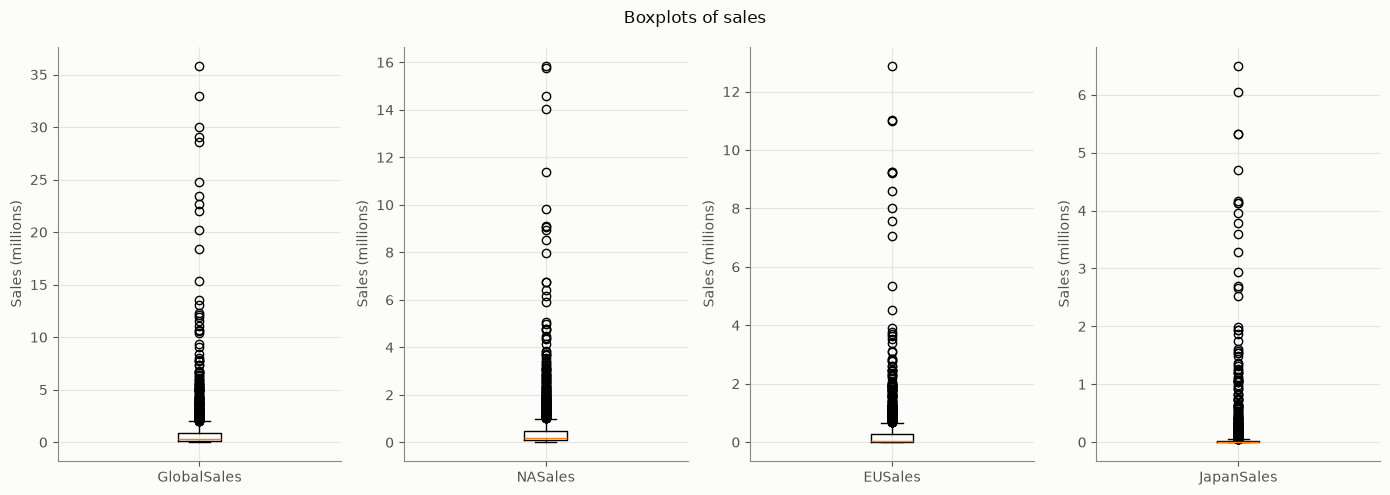

  -> saved output/q3/boxplots.png


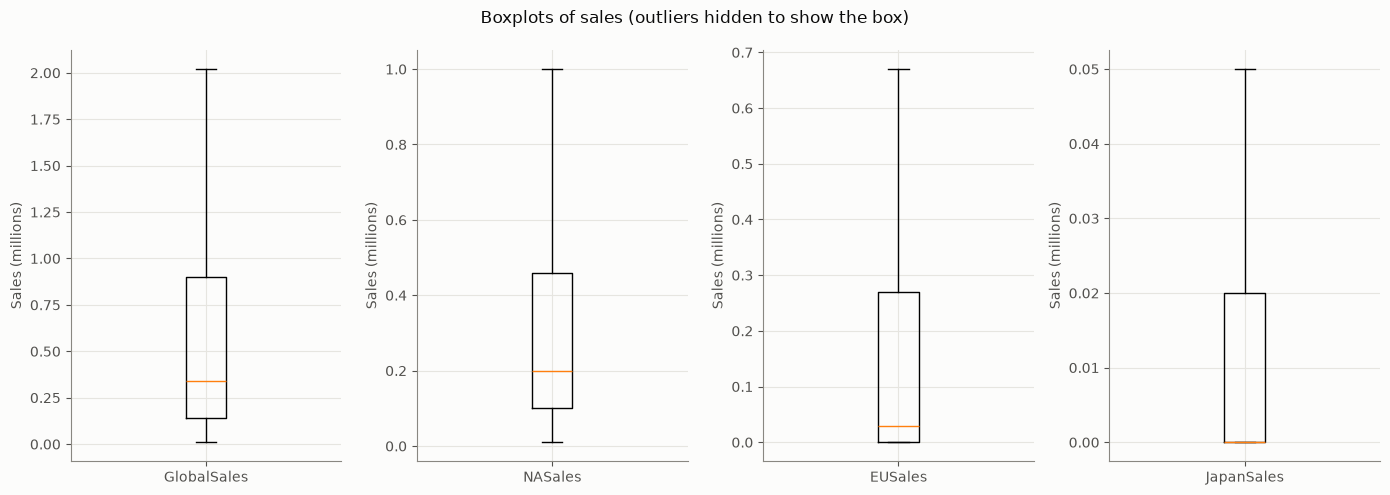

  -> saved output/q3/boxplots_no_outliers.png


In [20]:
out = output_folder("q3")
# with and without outliers (can barely see the boxes otherwise)
box_plot_versions = [
    ("boxplots", True, "Boxplots of sales"),
    ("boxplots_no_outliers", False, "Boxplots of sales (outliers hidden to show the box)"),
]
for file_name, show_outliers, title in box_plot_versions:
    fig, axes = plt.subplots(1, 4, figsize=(14, 5))
    for ax, column in zip(axes, ALL_SALES):
        ax.bxp([box_from_notes(column)], showfliers=show_outliers)
        ax.set_ylabel("Sales (millions)")
    fig.suptitle(title)
    save_figure(fig, out, file_name)

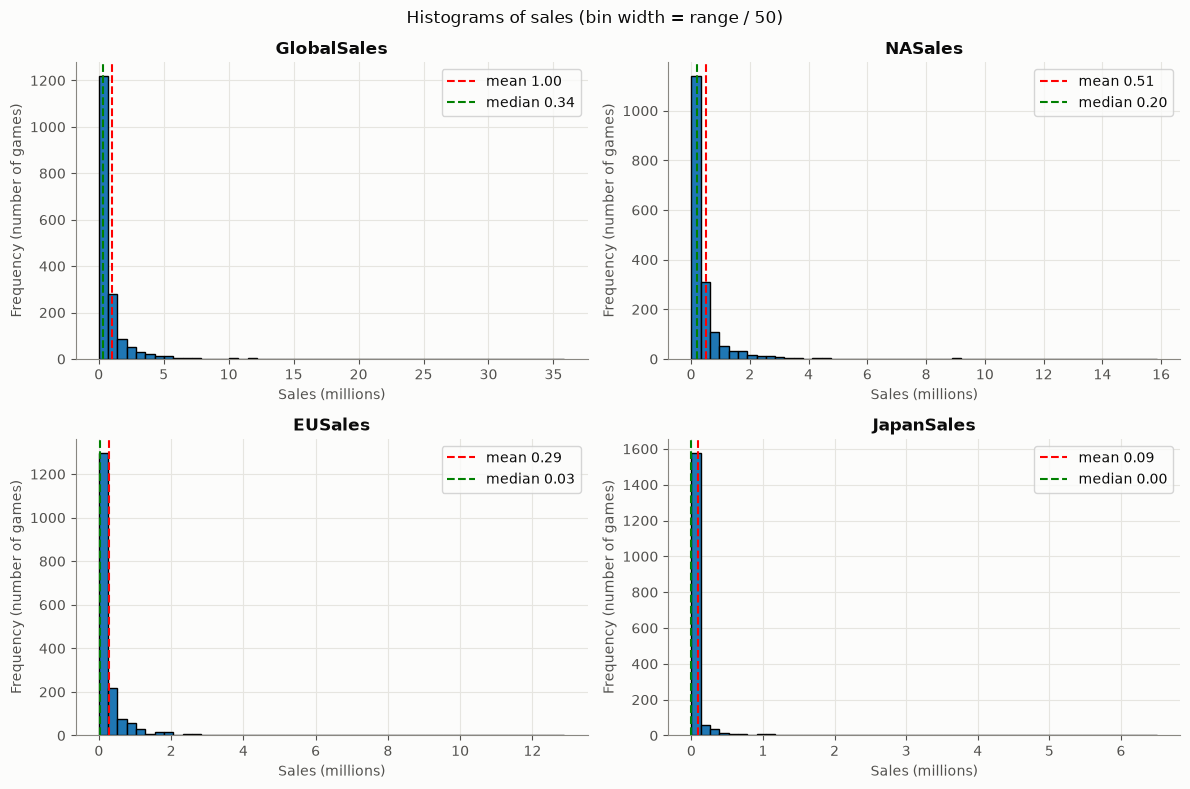

  -> saved output/q3/histograms.png


In [21]:
# histograms
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, ALL_SALES):
    sales = df[column]
    ax.hist(sales, bins=50, edgecolor="black")
    ax.axvline(sales.mean(), color="red", linestyle="--", label=f"mean {sales.mean():.2f}")
    ax.axvline(sales.median(), color="green", linestyle="--", label=f"median {sales.median():.2f}")
    ax.set_title(column)
    ax.set_xlabel("Sales (millions)")
    ax.set_ylabel("Frequency (number of games)")
    ax.legend()
fig.suptitle("Histograms of sales (bin width = range / 50)")
save_figure(fig, out, "histograms")

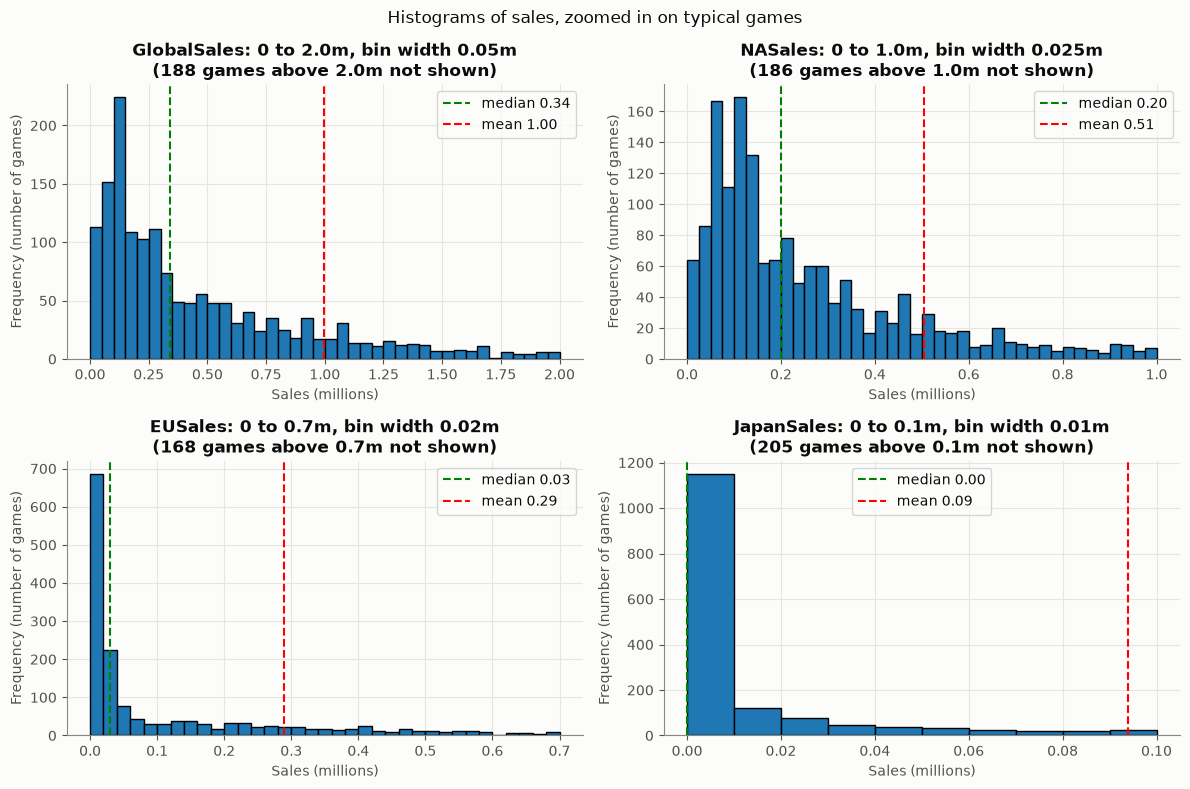

  -> saved output/q3/histograms_zoomed.png


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, ALL_SALES):
    upper, width = zoom_settings[column]
    sales = df[column]
    shown = sales[sales <= upper]
    bin_edges = [i * width for i in range(round(upper / width) + 1)]

    ax.hist(shown, bins=bin_edges, edgecolor="black")
    ax.axvline(sales.median(), color="green", linestyle="--", label=f"median {sales.median():.2f}")
    if sales.mean() <= upper:  # mean might be off the chart
        ax.axvline(sales.mean(), color="red", linestyle="--", label=f"mean {sales.mean():.2f}")

    n_hidden = len(sales) - len(shown)
    log.debug(f"{column} zoom: {len(bin_edges) - 1} bins, {n_hidden} hidden")
    ax.set_title(f"{column}: 0 to {upper}m, bin width {width}m\n({n_hidden} games above {upper}m not shown)")
    ax.set_xlabel("Sales (millions)")
    ax.set_ylabel("Frequency (number of games)")
    ax.legend()
fig.suptitle("Histograms of sales, zoomed in on typical games")
save_figure(fig, out, "histograms_zoomed")

## Q5 — Alternative-model scatter grid
Fit ln(Y) against X using Y > 0, and ln(Y) against ln(X) using X > 0 and Y > 0. The latter is beyond the lecture notes. Transformed-model correlations use different scales and subsets.

In [23]:
out = output_folder("q5")
display(models.round(4))

,X,Y,Model,n,m (gradient),b (y-intercept),r,Strength,X range in data,Equation,Check m = r * sY/sX
0,NASales,EUSales,Linear,1754,0.6711,-0.0502,0.8944,strong positive linear association,0.01 to 15.85,EUSales = 0.6711 * NASales - 0.0502,0.6711
1,NASales,ln(EUSales),"Exponential (ln Y vs X, Y > 0)",1272,0.6570,-2.6511,0.5121,moderate positive linear association,0.01 to 15.85,ln(EUSales) = 0.6570 * NASales - 2.6511 => E...,NaN
2,ln(NASales),ln(EUSales),"Power (ln Y vs ln X, beyond notes)",1272,0.9410,-1.1083,0.6427,moderate positive linear association,-4.60517 to 2.76317,ln(EUSales) = 0.9410 * ln(NASales) - 1.1083 =...,NaN
3,EUSales,NASales,Linear,1754,1.1920,0.1610,0.8944,strong positive linear association,0 to 12.88,NASales = 1.1920 * EUSales + 0.1610,1.1920
4,EUSales,ln(NASales),"Exponential (ln Y vs X, Y > 0)",1754,0.7637,-1.7542,0.5290,moderate positive linear association,0 to 12.88,ln(NASales) = 0.7637 * EUSales - 1.7542 => N...,NaN
5,ln(EUSales),ln(NASales),"Power (ln Y vs ln X, beyond notes)",1272,0.4390,-0.2116,0.6427,moderate positive linear association,-4.60517 to 2.55568,ln(NASales) = 0.4390 * ln(EUSales) - 0.2116 =...,NaN
6,NASales,JapanSales,Linear,1754,0.2540,-0.0344,0.6459,moderate positive linear association,0.01 to 15.85,JapanSales = 0.2540 * NASales - 0.0344,0.2540
7,NASales,ln(JapanSales),"Exponential (ln Y vs X, Y > 0)",604,0.3789,-3.0961,0.4383,moderate positive linear association,0.01 to 15.85,ln(JapanSales) = 0.3789 * NASales - 3.0961 =>...,NaN
8,ln(NASales),ln(JapanSales),"Power (ln Y vs ln X, beyond notes)",604,0.4271,-2.3424,0.3583,moderate positive linear association,-4.60517 to 2.76317,ln(JapanSales) = 0.4271 * ln(NASales) - 2.3424...,NaN
9,JapanSales,NASales,Linear,1754,1.6421,0.3512,0.6459,moderate positive linear association,0 to 6.5,NASales = 1.6421 * JapanSales + 0.3512,1.6421


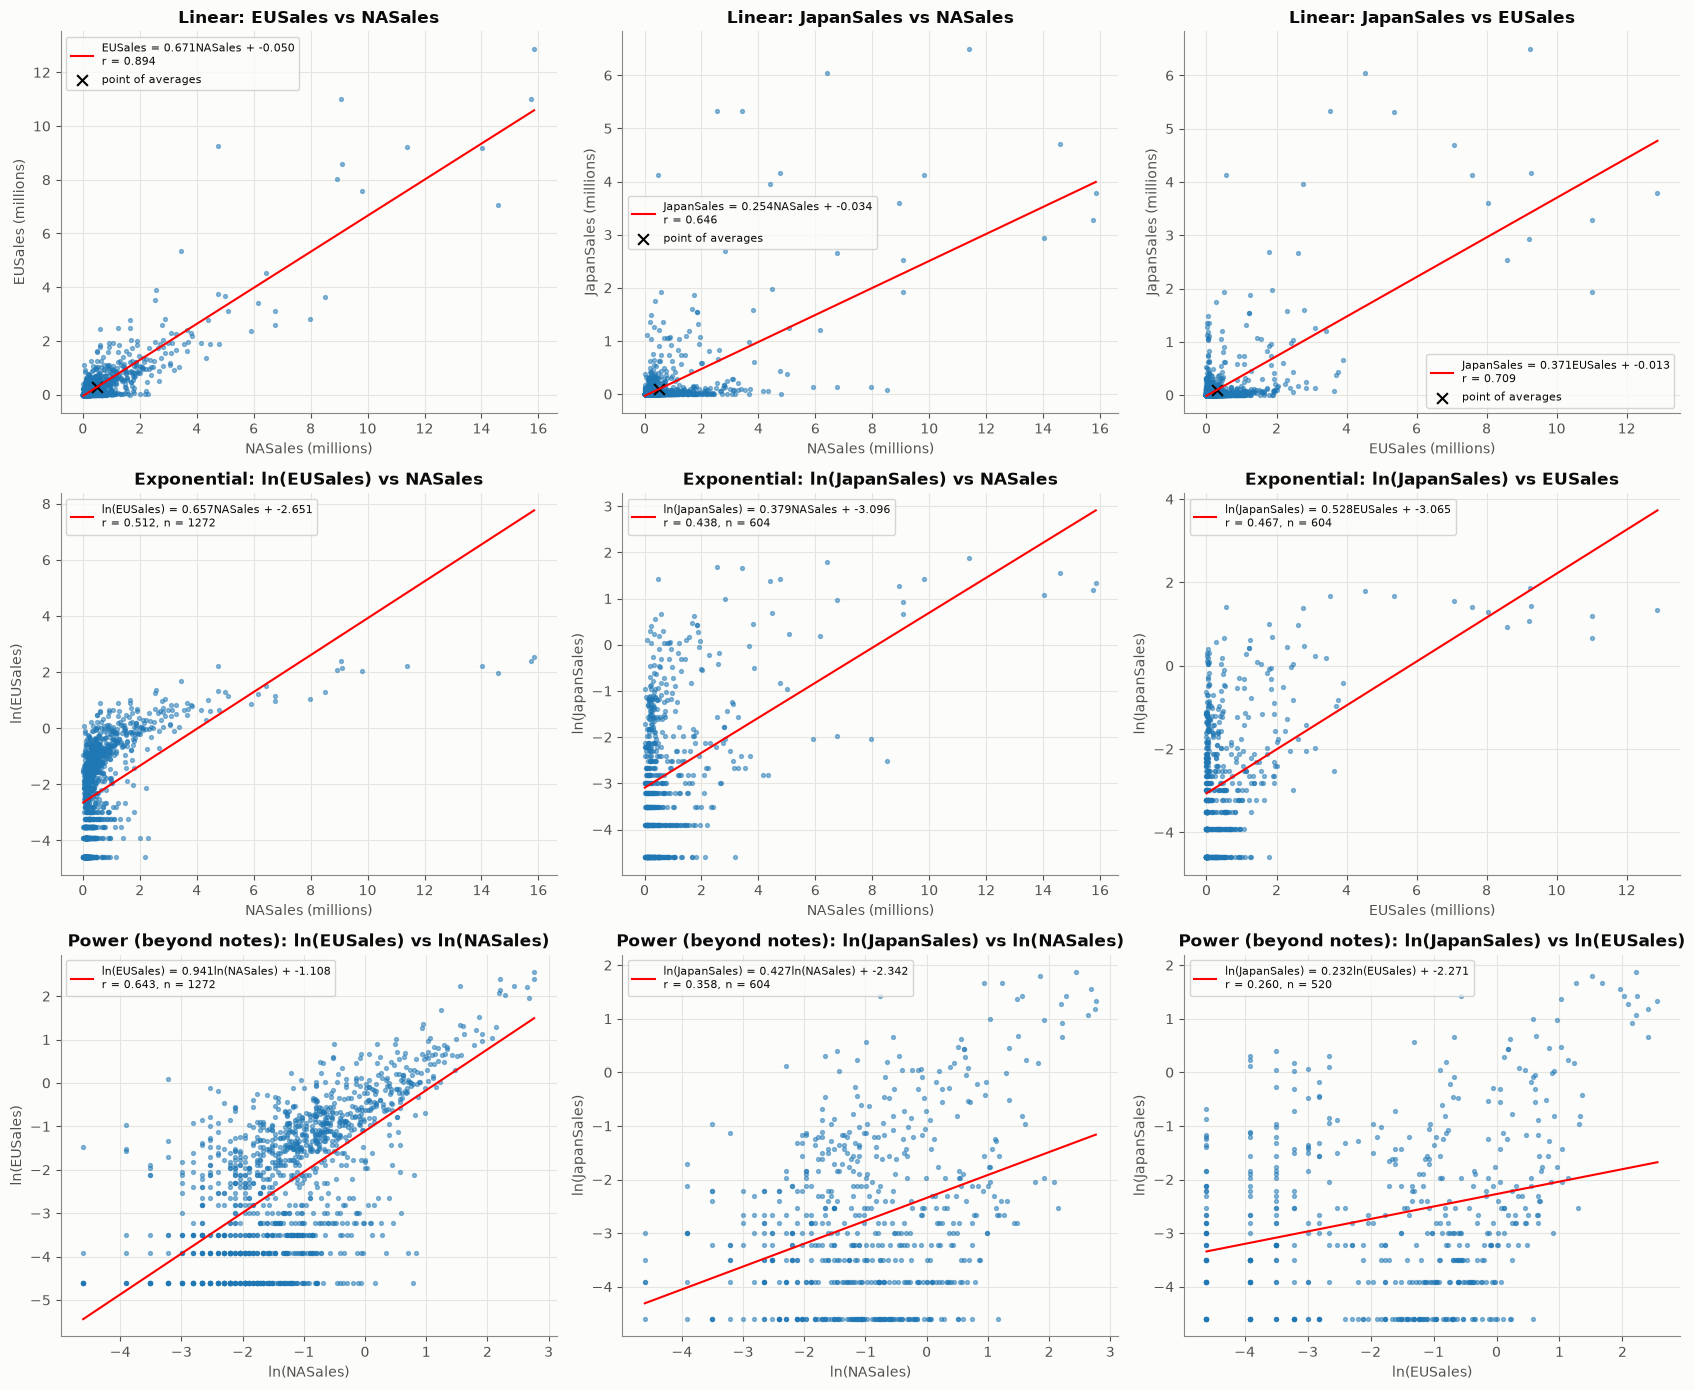

  -> saved output/q5/scatter_pairs.png


In [24]:
# scatter plots: columns = region pairs, rows = linear / exponential / power
def plot_fit(ax, x, y, label):
    result = stats.linregress(x, y)
    xs = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, y, s=8, alpha=0.5)
    ax.plot(xs, result.slope * xs + result.intercept, color="red", label=label(result))

fig, axes = plt.subplots(3, 3, figsize=(17, 14))
for i, (x_col, y_col) in enumerate(REGION_PAIRS):
    x = games[x_col]
    y = games[y_col]

    ax = axes[0, i]
    plot_fit(ax, x, y, lambda res: f"{y_col} = {res.slope:.3f}{x_col} + {res.intercept:.3f}\n"
                                    f"r = {res.rvalue:.3f}")
    ax.scatter([x.mean()], [y.mean()], color="black", marker="x", s=60, label="point of averages")
    ax.set(xlabel=f"{x_col} (millions)", ylabel=f"{y_col} (millions)", title=f"Linear: {y_col} vs {x_col}")
    ax.legend(fontsize=8)

    ax = axes[1, i]
    y_positive = y > 0
    plot_fit(ax, x[y_positive], np.log(y[y_positive]),
             lambda res: f"ln({y_col}) = {res.slope:.3f}{x_col} + {res.intercept:.3f}\n"
                         f"r = {res.rvalue:.3f}, n = {y_positive.sum()}")
    ax.set(xlabel=f"{x_col} (millions)", ylabel=f"ln({y_col})", title=f"Exponential: ln({y_col}) vs {x_col}")
    ax.legend(fontsize=8)

    ax = axes[2, i]
    both_positive = (x > 0) & (y > 0)
    plot_fit(ax, np.log(x[both_positive]), np.log(y[both_positive]),
             lambda res: f"ln({y_col}) = {res.slope:.3f}ln({x_col}) + {res.intercept:.3f}\n"
                         f"r = {res.rvalue:.3f}, n = {both_positive.sum()}")
    ax.set(xlabel=f"ln({x_col})", ylabel=f"ln({y_col})", title=f"Power (beyond notes): ln({y_col}) vs ln({x_col})")
    ax.legend(fontsize=8)

save_figure(fig, out, "scatter_pairs")

In [25]:
heading("Q5. Data quality notes for prediction")

for column in REGIONS:
    log.info(f"{column}: {(games[column] == 0).mean():.1%} of games have 0 sales; max = {games[column].max()}")

na_hits_zero_japan = ((games["JapanSales"] == 0) & (games["NASales"] > 1)).sum()
log.info(f"\nGames with JapanSales = 0 but NASales > 1m: {na_hits_zero_japan}")
log.info("Sales are given to two decimal places (0.01m), so many small values collapse onto the same few points.")


Q5. Data quality notes for prediction


NASales: 0.0% of games have 0 sales; max = 15.85


EUSales: 27.5% of games have 0 sales; max = 12.88


JapanSales: 65.6% of games have 0 sales; max = 6.5



Games with JapanSales = 0 but NASales > 1m: 47


Sales are given to two decimal places (0.01m), so many small values collapse onto the same few points.
